In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as io
import skimage.color as color
import skimage.transform as transform

## 1. Types of Digital Image & File I/O: koreaUniversity.jpg

### 1-1. Read `koreaUniversity.jpg` and display the image

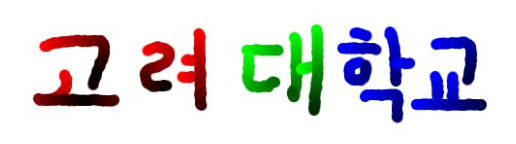

In [2]:
korea = io.imread('images/koreaUniversity.jpg')

plt.figure()
plt.imshow(korea)
plt.axis('off')
plt.show()

### 1-2. Display the R, G, and B planes separately

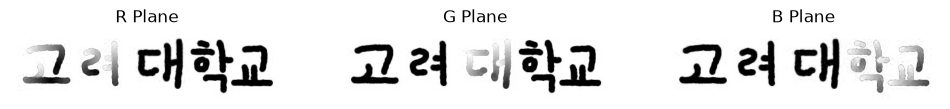

In [3]:
# Separate RGB planes

R = korea[:, :, 0]
G = korea[:, :, 1]
B = korea[:, :, 2]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray")
plt.title("R Plane")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray")
plt.title("G Plane")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray")
plt.title("B Plane")
plt.axis("off")

plt.show()

Q. Which character is the brightest when you display only the R 
plane of ‘korea’? 

A. '려'

### 1-3. RGB to Gray Conversion

#### (a) Convert the RGB image into a gray image

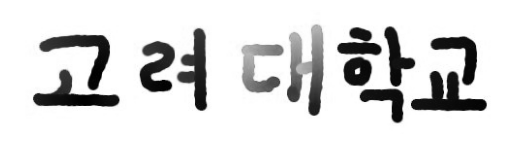

In [4]:
korea_gray = color.rgb2gray(korea)

plt.figure()
plt.imshow(korea_gray, cmap="gray")
plt.axis("off")
plt.show()

#### (b) Save the gray image as `korea_gray.jpg`

In [5]:
from skimage import img_as_ubyte

korea_gray_uint8 = img_as_ubyte(korea_gray)
io.imsave("images/korea_gray.jpg", korea_gray_uint8)

#### (c) Compare the sizes of `koreaUniversity.jpg` and `korea_gray.jpg`

In [7]:
import os

original_size = os.path.getsize("images/koreaUniversity.jpg")
gray_size = os.path.getsize("images/korea_gray.jpg")

print("koreaUniversity.jpg:", original_size, "bytes")
print("korea_gray.jpg:", gray_size, "bytes")

koreaUniversity.jpg: 12501 bytes
korea_gray.jpg: 8501 bytes


**Answer:**  
- `koreaUniversity.jpg`: 12,501 bytes  
- `korea_gray.jpg`: 8,501 bytes  

The grayscale image has a smaller file size than the original RGB image. The grayscale image is 4,000 bytes smaller than the original RGB image.

## 2. Types of Digital Image & File I/O

### 2-1. Read `lena.txt` and convert the pixel values to floating point

In [8]:
lena_txt = np.loadtxt("images/lena.txt", dtype=float)

print("Shape:", lena_txt.shape)
print("Data type:", lena_txt.dtype)

Shape: (256, 256)
Data type: float64


### 2-2. Read `lena.bmp` and proportionally adjust the pixel values from 0 to 127

In [9]:
lena_bmp = io.imread("images/lena.bmp")

lena_127 = lena_bmp.astype(float) * 127 / 255

print("Original range:", lena_bmp.min(), "~", lena_bmp.max())
print("Adjusted range:", lena_127.min(), "~", lena_127.max())

Original range: 3 ~ 239
Adjusted range: 1.4941176470588236 ~ 119.03137254901961


### 2-3. Display the two matrices using 0–255 grayscale and describe the difference

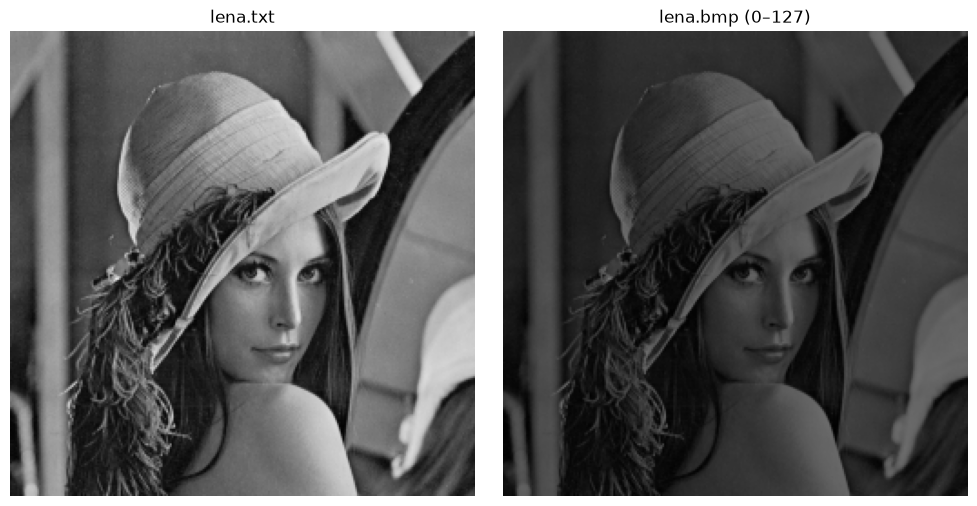

In [10]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(lena_txt, cmap="gray", vmin=0, vmax=255)
plt.title("lena.txt")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lena_127, cmap="gray", vmin=0, vmax=255)
plt.title("lena.bmp (0–127)")
plt.axis("off")

plt.tight_layout()
plt.show()

**Answer:**  
The adjusted `lena.bmp` appears darker than `lena.txt` due to its reduced pixel intensity range (0–127), while the overall image structure remains unchanged.

## 3. Sampling

### 3-1. Read `lena.bmp`

In [11]:
lena = io.imread("images/lena.bmp")

### 3-2. Reduce the number of rows and columns by 1/2, 1/4, and 1/8

In [12]:
lena_half = transform.rescale(lena, 1/2, order=0)
lena_quarter = transform.rescale(lena, 1/4, order=0)
lena_eighth = transform.rescale(lena, 1/8, order=0)

print("Original:", lena.shape)
print("1/2:", lena_half.shape)
print("1/4:", lena_quarter.shape)
print("1/8:", lena_eighth.shape)

Original: (256, 256)
1/2: (128, 128)
1/4: (64, 64)
1/8: (32, 32)


### 3-2. Restore the reduced images to the original size using `order=0`

In [13]:
lena_half_restored = transform.rescale(lena_half, 2, order=0)
lena_quarter_restored = transform.rescale(lena_quarter, 4, order=0)
lena_eighth_restored = transform.rescale(lena_eighth, 8, order=0)

print("Original:", lena.shape)
print("1/2 restored:", lena_half_restored.shape)
print("1/4 restored:", lena_quarter_restored.shape)
print("1/8 restored:", lena_eighth_restored.shape)

Original: (256, 256)
1/2 restored: (256, 256)
1/4 restored: (256, 256)
1/8 restored: (256, 256)


### 3-3. Display the original and restored images in a single figure

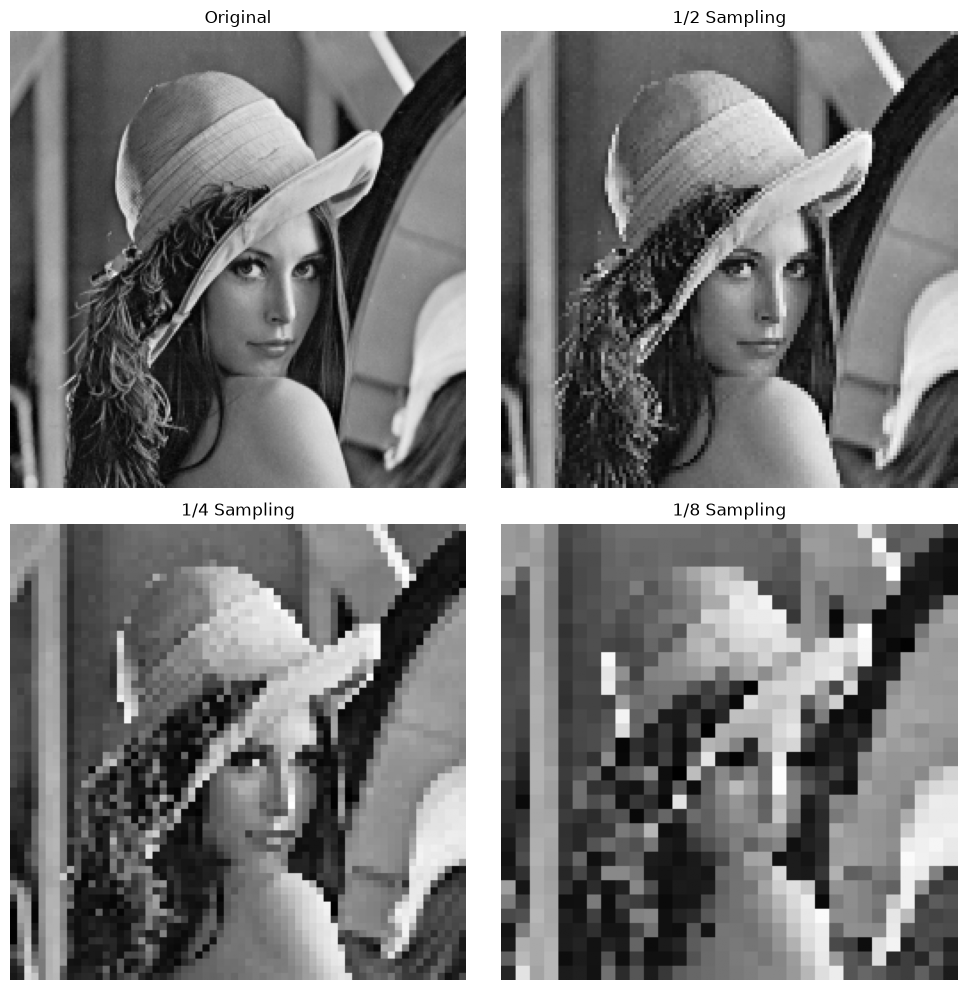

In [14]:
plt.figure(figsize=(10, 10))

plt.subplot(2, 2, 1)
plt.imshow(lena, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(lena_half_restored, cmap="gray")
plt.title("1/2 Sampling")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(lena_quarter_restored, cmap="gray")
plt.title("1/4 Sampling")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(lena_eighth_restored, cmap="gray")
plt.title("1/8 Sampling")
plt.axis("off")

plt.tight_layout()
plt.show()

### 3-4. Observation of image degradation

**Observation:**  
As the sampling rate decreases, pixelation becomes more severe and fine details are lost. The hair texture becomes increasingly blocky, the facial features become less smooth and less distinguishable, and the curved edges and texture of the hat become jagged and coarse. The degradation is most noticeable in the 1/8 sampled image.

## 4. Bit Plane

### 4-1. Generate and display all bit planes of `lena.bmp`

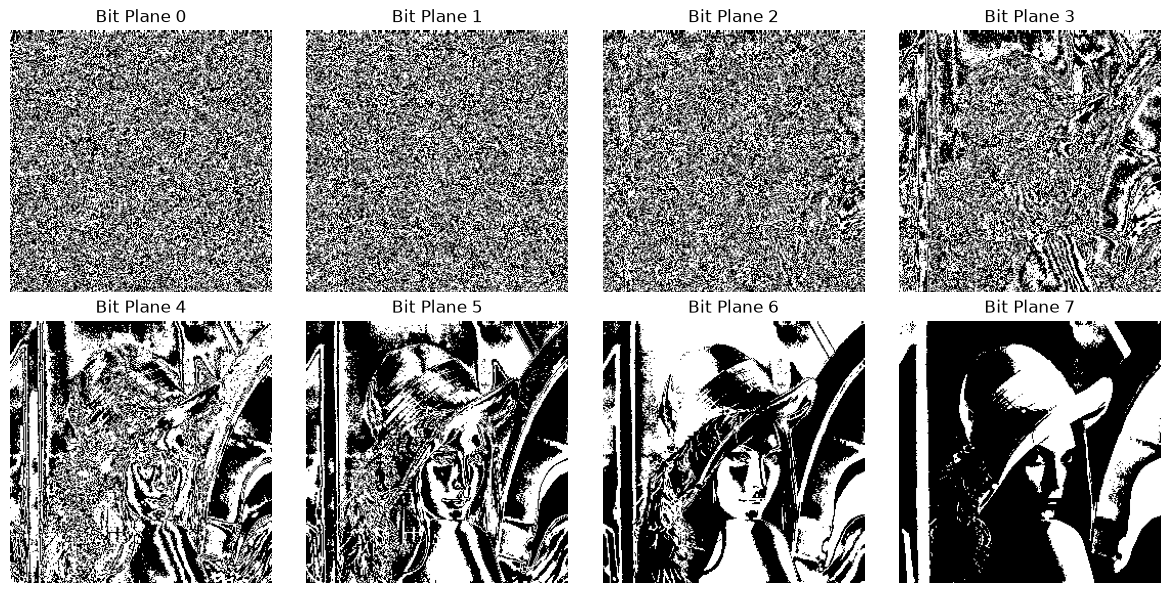

In [15]:
bit_planes = []

for i in range(8):
    plane = (lena >> i) % 2
    bit_planes.append(plane)

plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(bit_planes[i], cmap="gray")
    plt.title(f"Bit Plane {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 4-2. Combine the two MSB planes

In [16]:
two_MSB = bit_planes[7] * (2**7) + bit_planes[6] * (2**6)

### 4-3. Combine the four MSB planes

In [17]:
four_MSB = (bit_planes[7] * (2**7) +
            bit_planes[6] * (2**6) +
            bit_planes[5] * (2**5) +
            bit_planes[4] * (2**4))


### 4-4. Combine the four LSB planes

In [18]:
four_LSB = (bit_planes[3] * (2**3) +
            bit_planes[2] * (2**2) +
            bit_planes[1] * (2**1) +
            bit_planes[0] * (2**0))

### 4-5. Display the combined images in a single figure

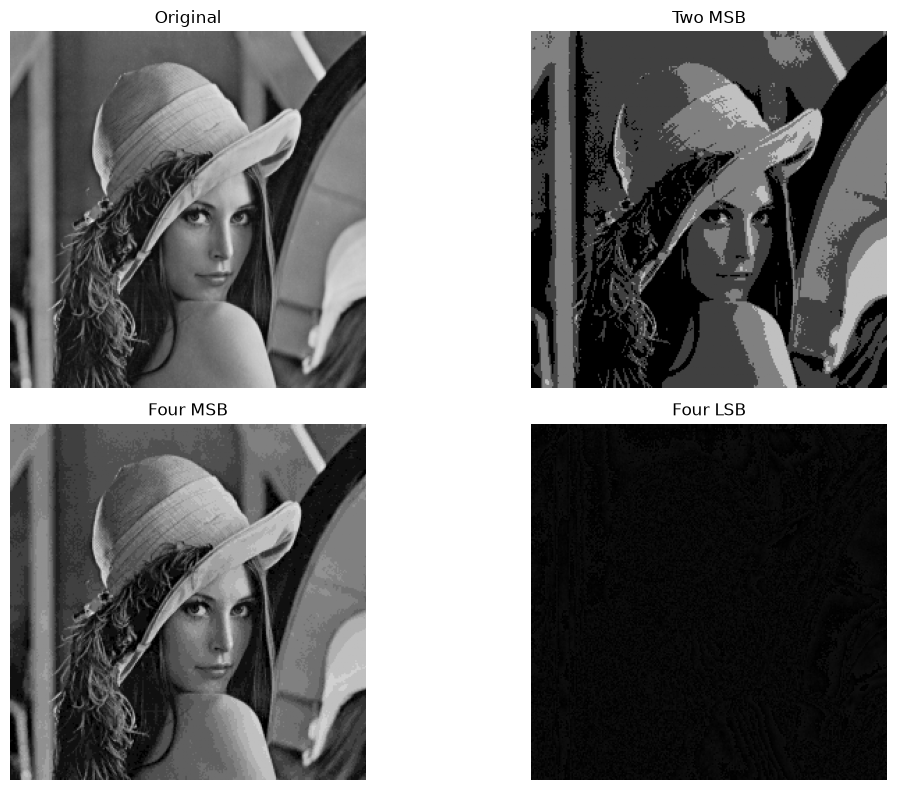

In [19]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(lena, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(two_MSB, cmap="gray", vmin=0, vmax=255)
plt.title("Two MSB")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(four_MSB, cmap="gray", vmin=0, vmax=255)
plt.title("Four MSB")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(four_LSB, cmap="gray", vmin=0, vmax=255)
plt.title("Four LSB")
plt.axis("off")

plt.tight_layout()
plt.show()

### 4-6. Which one is the closest to the original image?

**Answer:**  
The image reconstructed from the **four MSB planes** is the closest to the original image. The four MSBs preserve most of the important visual information, while the two MSBs lose more intensity detail and the four LSBs contain relatively little information about the overall image structure.